# Classificação DORA de referência (C1) (Issue #65)

C1 é a combinação de referência da RQ07: **unidade de *deploy* = *release* publicada, *lead time* (a) por *release*
e CFR (a) proxy de CI**, mais o tempo de recuperação. Cada métrica é classificada em Elite / High / Medium / Low pela
tabela da disciplina (`metrics/classificacao.py`), e a categoria geral é a mediana das notas (Elite = 4, …, Low = 1)
arredondada para baixo. Métricas sem valor (por exemplo, nenhum episódio de falha recuperado) ficam fora da mediana.

Lê só `lab03/code/data/dataset_dora.csv` e exporta `lab03/code/data/classificacao_c1.csv`, base da análise de
sensibilidade (RQ07, Issue #68).

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALISE = Path.cwd()
CODE = ANALISE.parent / "code"
sys.path.insert(0, str(CODE))
from metrics.classificacao import ELITE, HIGH, MEDIUM, LOW, NOTAS, categorias_repositorio

FIGURAS = ANALISE / "figuras"
TABELAS = ANALISE / "tabelas"
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

df = pd.read_csv(CODE / "data" / "dataset_dora.csv")
print(f"{len(df)} repositórios")

300 repositórios


## Classificação de cada repositório

In [2]:
METRICAS_C1 = {
    "deploy_frequency": "deploy_freq_release",
    "lead_time": "lead_time_a_horas",
    "cfr": "cfr_a",
    "tempo_recuperacao": "tempo_recuperacao_horas",
}


def valor(v):
    return None if pd.isna(v) else float(v)


cats = pd.DataFrame(
    [categorias_repositorio(*(valor(r[c]) for c in METRICAS_C1.values())) for _, r in df.iterrows()],
    index=df.index,
)

# Confere com as colunas c1_* gravadas por gerar_dataset.py
for nome in cats.columns:
    gravada = df[f"c1_{nome}"].where(df[f"c1_{nome}"].notna(), None)
    assert (cats[nome].fillna("-") == gravada.fillna("-")).all(), nome
print("Classificação recalculada igual à do dataset.")

c1 = df[["full_name", *METRICAS_C1.values()]].copy()
for nome in METRICAS_C1:
    c1[f"cat_{nome}"] = cats[nome]
    c1[f"nota_{nome}"] = cats[nome].map(NOTAS).astype("Int64")
notas = c1[[f"nota_{n}" for n in METRICAS_C1]]
c1["n_metricas_classificadas"] = notas.notna().sum(axis=1)
c1["mediana_notas"] = notas.astype(float).median(axis=1)
c1["categoria_geral"] = cats["geral"]
c1.to_csv(CODE / "data" / "classificacao_c1.csv", index=False)
print(f"Exportado classificacao_c1.csv com {len(c1)} linhas")
c1.head()

Classificação recalculada igual à do dataset.
Exportado classificacao_c1.csv com 300 linhas


,full_name,deploy_freq_release,lead_time_a_horas,cfr_a,tempo_recuperacao_horas,cat_deploy_frequency,nota_deploy_frequency,cat_lead_time,nota_lead_time,cat_cfr,nota_cfr,cat_tempo_recuperacao,nota_tempo_recuperacao,n_metricas_classificadas,mediana_notas,categoria_geral
0,917Dhj/DeepPaperNote,0.287671,119.875833,0.042105,0.357500,Medium,2,High,3,Elite,4,Elite,4,4,3.5,High
1,AcademySoftwareFoundation/openexr,0.652055,14591.153194,0.018915,31.012917,Medium,2,Low,1,Elite,4,Medium,2,4,2.0,Medium
2,Agents365-ai/drawio-skill,0.863014,2.607500,0.210526,0.673611,Medium,2,Elite,4,High,3,Elite,4,4,3.5,High
3,Aidoku/Aidoku,0.153425,945.882222,0.039711,1.206389,Low,1,Low,1,Elite,4,High,3,4,2.0,Medium
4,AndyHazz/bookshelf.koplugin,2.665753,5.054722,0.052632,34.916111,High,3,Elite,4,Elite,4,Medium,2,4,3.5,High


## Distribuição Elite / High / Medium / Low por métrica e geral

In [3]:
ORDEM = [ELITE, HIGH, MEDIUM, LOW]
ROTULOS = {"deploy_frequency": "Deployment frequency", "lead_time": "Lead time (a)", "cfr": "CFR (a)",
           "tempo_recuperacao": "Tempo de recuperação", "geral": "Geral (C1)"}
colunas = {**{n: f"cat_{n}" for n in METRICAS_C1}, "geral": "categoria_geral"}

contagem = pd.DataFrame({
    ROTULOS[n]: c1[col].value_counts().reindex(ORDEM, fill_value=0) for n, col in colunas.items()
}).T
contagem["sem valor"] = len(c1) - contagem.sum(axis=1)
percentual = contagem[ORDEM].div(contagem[ORDEM].sum(axis=1), axis=0) * 100

tabela = contagem.astype(str) + " (" + percentual.reindex(columns=contagem.columns).round(1).astype(str) + "%)"
tabela["sem valor"] = contagem["sem valor"].astype(str)
pd.concat({"n": contagem, "%": percentual.round(1)}, axis=1).to_csv(TABELAS / "c1_distribuicao.csv")
tabela

,Elite,High,Medium,Low,sem valor
Deployment frequency,3 (1.0%),50 (16.7%),149 (49.7%),98 (32.7%),0
Lead time (a),48 (16.1%),77 (25.8%),93 (31.1%),81 (27.1%),1
CFR (a),232 (77.3%),45 (15.0%),13 (4.3%),10 (3.3%),0
Tempo de recuperação,76 (27.5%),147 (53.3%),43 (15.6%),10 (3.6%),24
Geral (C1),17 (5.7%),125 (41.7%),137 (45.7%),21 (7.0%),0


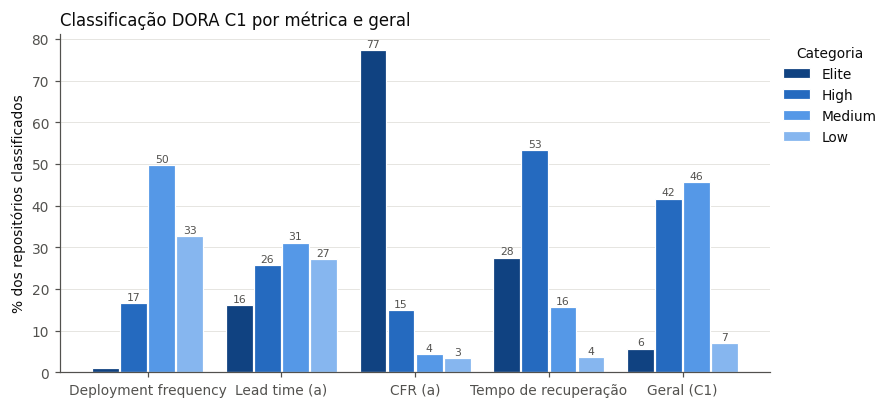

In [4]:
# Rampa ordinal azul: Elite mais escuro, Low mais claro (passo 250 é o mais claro permitido no fundo claro)
CORES = {ELITE: "#104281", HIGH: "#256abf", MEDIUM: "#5598e7", LOW: "#86b6ef"}
TEXTO, TEXTO_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 9,
    "axes.edgecolor": TEXTO_2, "axes.labelcolor": TEXTO, "text.color": TEXTO,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
grupos = list(percentual.index)
x = np.arange(len(grupos))
largura = 0.2
for i, cat in enumerate(ORDEM):
    pos = x + (i - 1.5) * (largura + 0.01)
    barras = ax.bar(pos, percentual[cat], width=largura, color=CORES[cat], label=cat, edgecolor="white", linewidth=0.8)
    for b, v in zip(barras, percentual[cat]):
        if v >= 3:
            ax.annotate(f"{v:.0f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 2),
                        textcoords="offset points", ha="center", fontsize=7, color=TEXTO_2)
ax.set_xticks(x, grupos)
ax.set_ylabel("% dos repositórios classificados")
ax.grid(axis="x", visible=False)
ax.legend(title="Categoria", frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Classificação DORA C1 por métrica e geral", loc="left")
fig.savefig(FIGURAS / "c1_distribuicao.png")

## O que puxa a categoria geral

Para cada repositório, a métrica com a pior nota (empates contam para todas as métricas empatadas) e o quanto a
categoria geral se afasta da melhor métrica.

In [5]:
pior = notas.astype(float).eq(notas.astype(float).min(axis=1), axis=0)
print("Métrica com a pior nota (% dos repositórios; empates contam para todas):")
print((pior.mean() * 100).round(1).rename(lambda c: ROTULOS[c.removeprefix("nota_")]).to_string())

print("\nNotas médias por métrica (Elite = 4 ... Low = 1):")
print(notas.astype(float).mean().round(2).rename(lambda c: ROTULOS[c.removeprefix("nota_")]).to_string())
print(f"\nRepositórios com as 4 métricas classificadas: {(c1.n_metricas_classificadas == 4).sum()} de {len(c1)}")

Métrica com a pior nota (% dos repositórios; empates contam para todas):
Deployment frequency    82.3
Lead time (a)           49.3
CFR (a)                  7.7
Tempo de recuperação    14.7

Notas médias por métrica (Elite = 4 ... Low = 1):
Deployment frequency    1.86
Lead time (a)           2.31
CFR (a)                 3.66
Tempo de recuperação    3.05

Repositórios com as 4 métricas classificadas: 275 de 300


In [6]:
# Cruzamento das categorias de velocidade (frequência) e de estabilidade (CFR a)
pd.crosstab(pd.Categorical(c1.cat_deploy_frequency, ORDEM), pd.Categorical(c1.cat_cfr, ORDEM),
            rownames=["Deployment frequency"], colnames=["CFR (a)"], dropna=False)

CFR (a),Elite,High,Medium,Low
Deployment frequency,,,,
Elite,2,1,0,0
High,39,6,4,1
Medium,116,21,6,6
Low,75,17,3,3
